## MTH786P 2025/2026 Final Project: Analysing the Diabetes Dataset
#### Student ID: 251057619

### 1. Imports

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score, confusion_matrix, classification_report,
    roc_auc_score, RocCurveDisplay
)

### 2. Load and inspect

In [2]:
import pandas as pd

df = pd.read_csv("/Users/nafisanokib/Desktop/QM/Machine Learning with Python/Final Project/DIABETES/diabetes.csv")
print(df.head())
print(df['Outcome'].value_counts())

   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  
Outcome
0    500
1    268
Name: count, dtype: int64


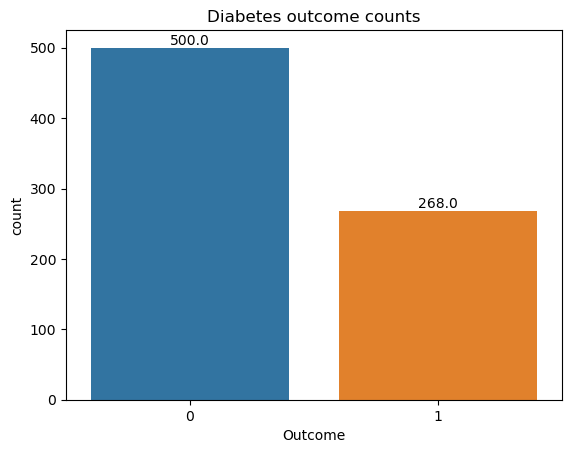

In [3]:
### outcome count plot with labels

ax = sns.countplot(x='Outcome', data=df)
plt.title('Diabetes outcome counts')
for p in ax.patches:
    height = p.get_height()
    ax.text(
        p.get_x() + p.get_width() / 2,
        height,
        str(height),
        ha='center',
        va='bottom'
    )
plt.show()

### 3. EDA + Graphs

In [4]:
print(df.shape)
print(df.describe())
print(df['Outcome'].value_counts(normalize=True))

(768, 9)
       Pregnancies     Glucose  BloodPressure  SkinThickness     Insulin  \
count   768.000000  768.000000     768.000000     768.000000  768.000000   
mean      3.845052  120.894531      69.105469      20.536458   79.799479   
std       3.369578   31.972618      19.355807      15.952218  115.244002   
min       0.000000    0.000000       0.000000       0.000000    0.000000   
25%       1.000000   99.000000      62.000000       0.000000    0.000000   
50%       3.000000  117.000000      72.000000      23.000000   30.500000   
75%       6.000000  140.250000      80.000000      32.000000  127.250000   
max      17.000000  199.000000     122.000000      99.000000  846.000000   

              BMI  DiabetesPedigreeFunction         Age     Outcome  
count  768.000000                768.000000  768.000000  768.000000  
mean    31.992578                  0.471876   33.240885    0.348958  
std      7.884160                  0.331329   11.760232    0.476951  
min      0.000000         

### Univariate distributions (per feature)

/opt/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


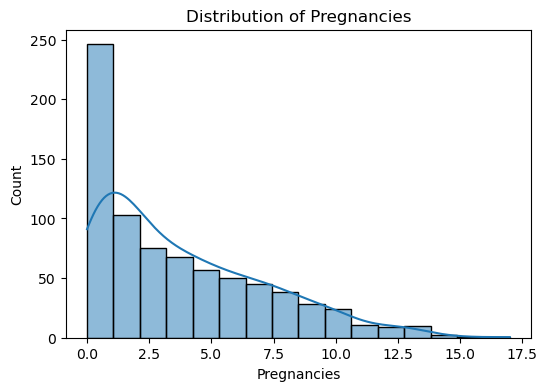

/opt/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


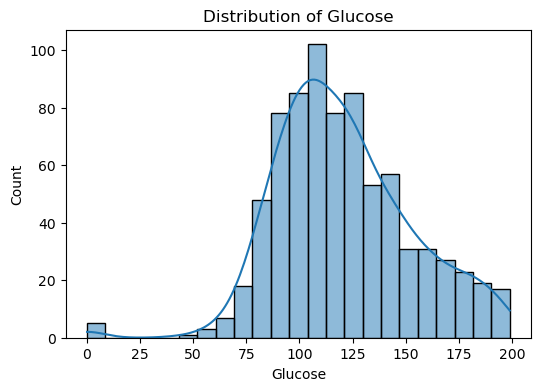

/opt/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


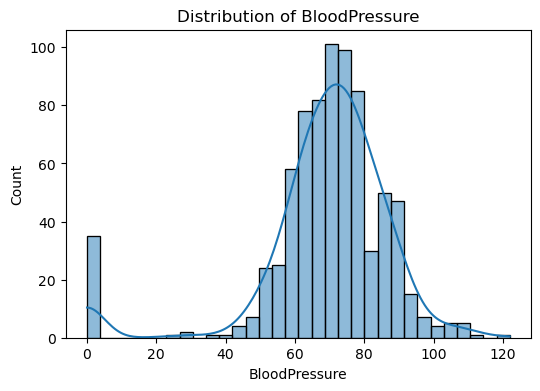

/opt/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


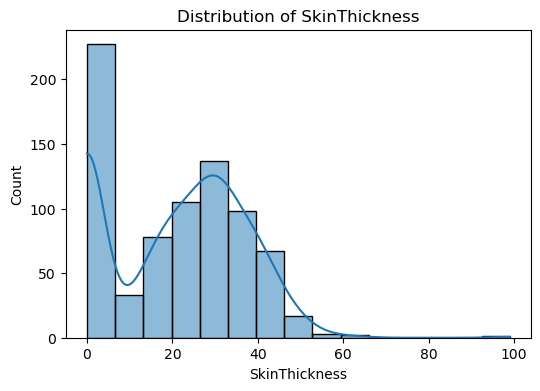

/opt/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


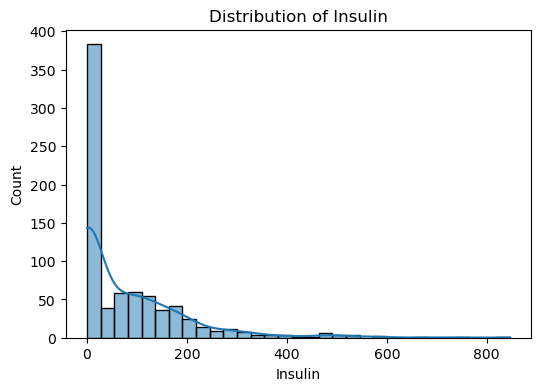

/opt/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


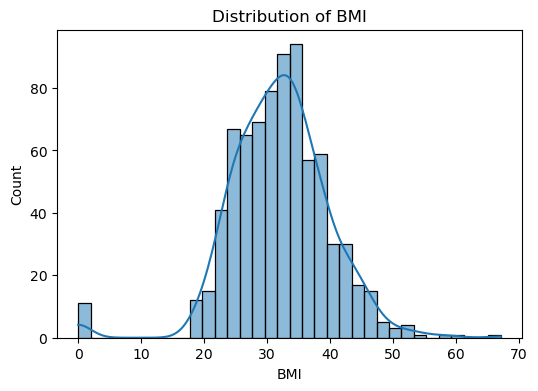

/opt/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


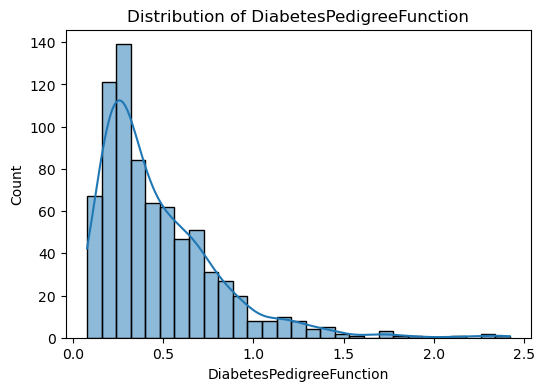

/opt/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


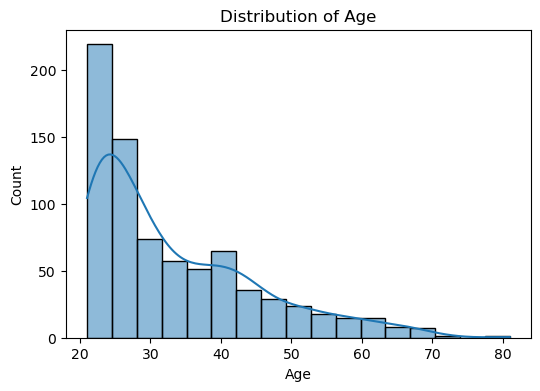

In [6]:
for col in df.columns:
    if col == 'Outcome': 
        continue
    plt.figure(figsize=(6,4))
    sns.histplot(df[col], kde=True)
    plt.title(f'Distribution of {col}')
    plt.show()

### Outcome-wise distributions

/opt/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


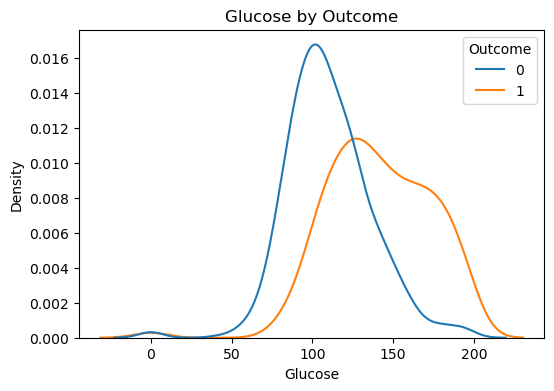

/opt/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


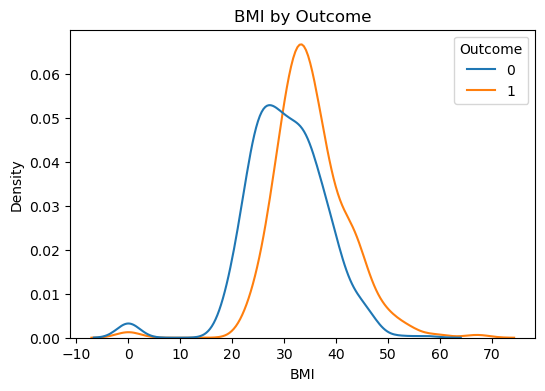

/opt/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


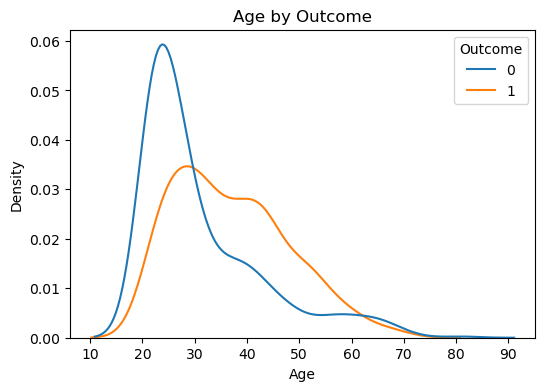

/opt/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


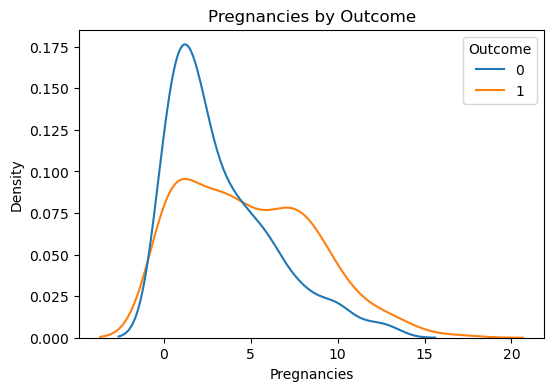

In [7]:
for col in ['Glucose', 'BMI', 'Age', 'Pregnancies']:
    plt.figure(figsize=(6,4))
    sns.kdeplot(data=df, x=col, hue='Outcome', common_norm=False)
    plt.title(f'{col} by Outcome')
    plt.show()


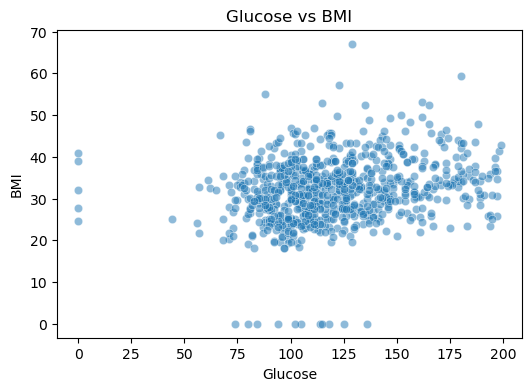

          Glucose       BMI
Glucose  1.000000  0.221071
BMI      0.221071  1.000000


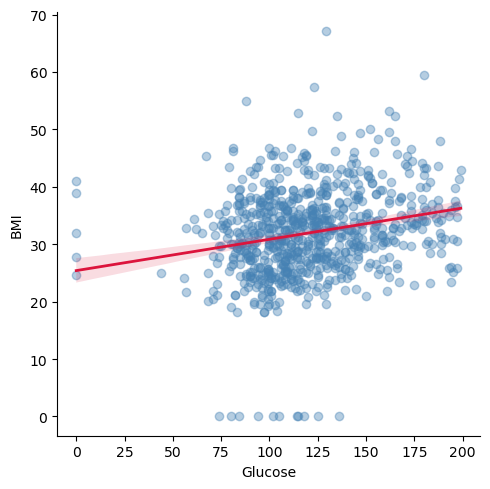

In [25]:
plt.figure(figsize=(6,4))
sns.scatterplot(data=df, x="Glucose", y="BMI", alpha=0.5)
plt.title("Glucose vs BMI")
plt.show()

sns.lmplot(
    data=df,
    x="Glucose",
    y="BMI",
    scatter_kws={"alpha": 0.4, "color": "steelblue"},
    line_kws={"color": "crimson", "linewidth": 2}
)
print(df[["Glucose","BMI"]].corr())


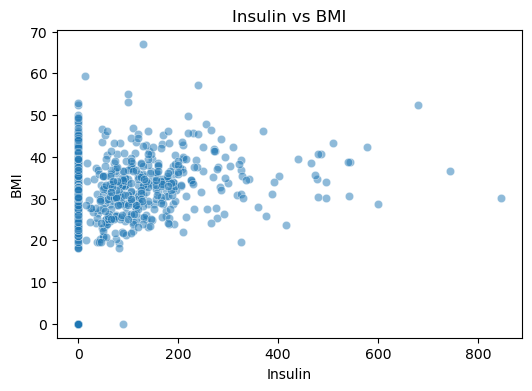

          Insulin       BMI
Insulin  1.000000  0.197859
BMI      0.197859  1.000000


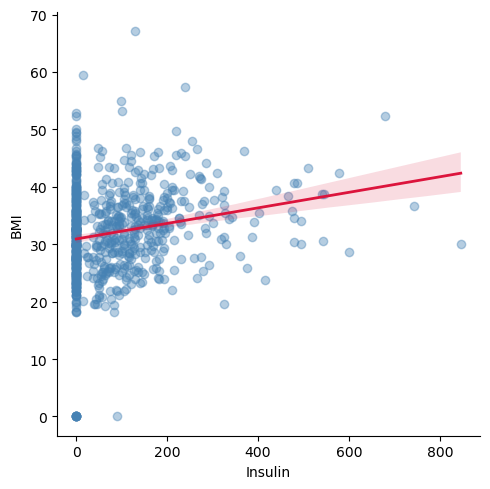

In [27]:
plt.figure(figsize=(6,4))
sns.scatterplot(data=df, x="Insulin", y="BMI", alpha=0.5)
plt.title("Insulin vs BMI")
plt.show()

sns.lmplot(
    data=df,
    x="Insulin",
    y="BMI",
    scatter_kws={"alpha": 0.4, "color": "steelblue"},
    line_kws={"color": "crimson", "linewidth": 2}
)
print(df[["Insulin","BMI"]].corr())


### Correlation / Scatterplots

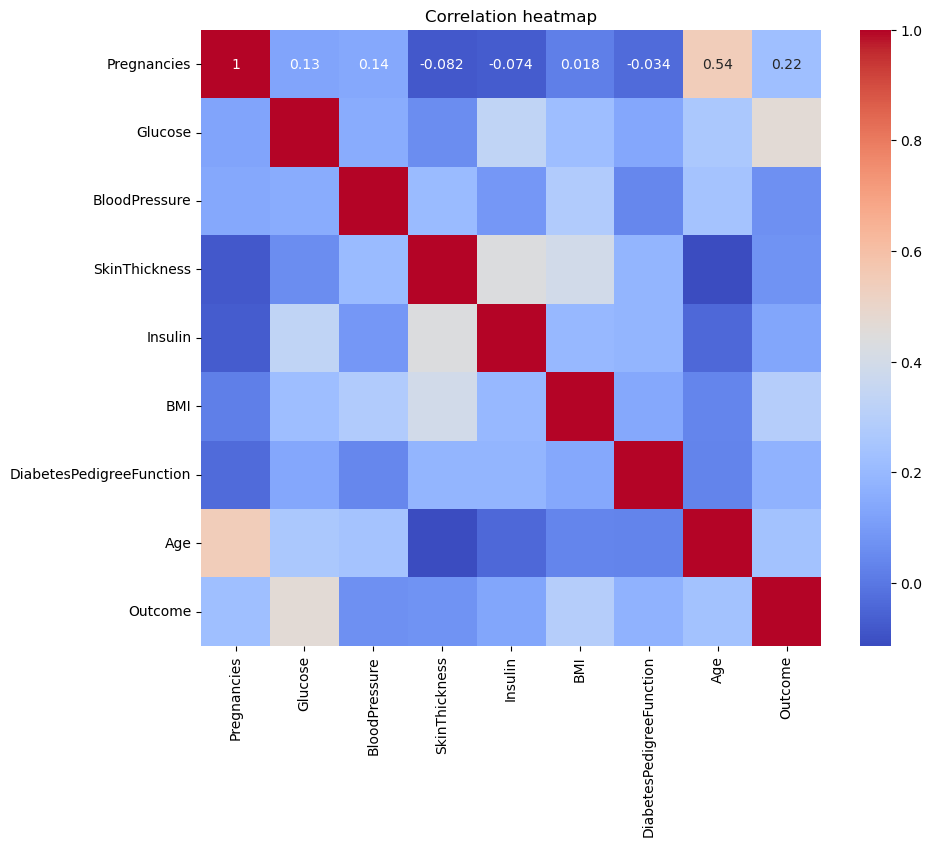

In [8]:
plt.figure(figsize=(10,8))
corr = df.corr(numeric_only=True)
sns.heatmap(corr, annot=True, cmap='coolwarm')
plt.title('Correlation heatmap')
plt.show()

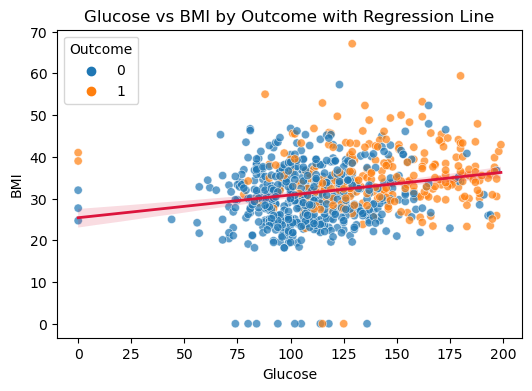

In [31]:
plt.figure(figsize=(6,4))
ax = sns.scatterplot(
    x='Glucose', y='BMI',
    hue='Outcome', data=df,
    alpha=0.7
)

sns.regplot(
    x='Glucose', y='BMI',
    data=df,
    scatter=False,
    ax=ax,
    color='crimson',
    line_kws={'linewidth': 2}
)

plt.title('Glucose vs BMI by Outcome with Regression Line')
plt.show()

### Missingness / zeros

In [10]:
# In this dataset, many variables use 0 as 'missing-like so we will be checking the zeros

zero_counts = (df == 0).sum()
print(zero_counts)

Pregnancies                 111
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                     500
dtype: int64


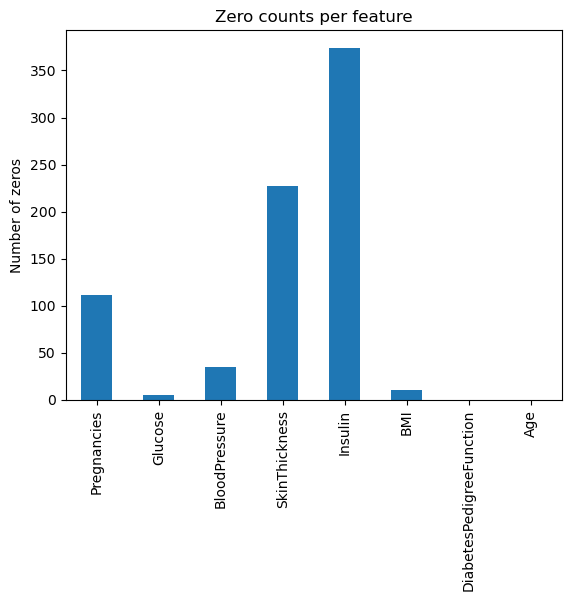

In [11]:
#Plot for key features and dropping 'outcome'

zero_counts.drop('Outcome').plot(kind='bar')
plt.title('Zero counts per feature')
plt.ylabel('Number of zeros')
plt.show()

### Defining features anf target, train/test split

In [12]:
X = df.drop(columns=['Outcome'])
y = df['Outcome']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=0, stratify=y
)

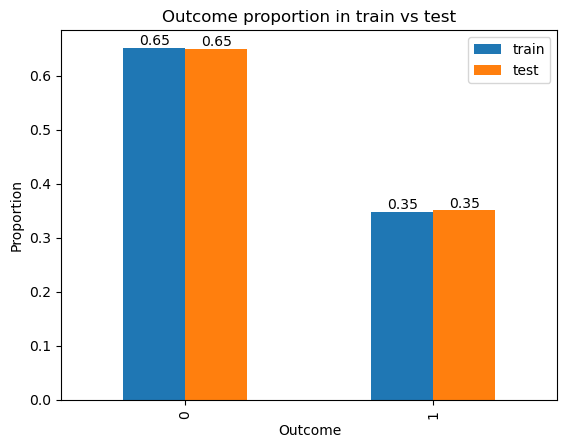

In [13]:
#Visualise split proportions with labels:

train_counts = y_train.value_counts(normalize=True).rename('train')
test_counts = y_test.value_counts(normalize=True).rename('test')

split_df = pd.concat([train_counts, test_counts], axis=1)

ax = split_df.plot(kind='bar')
ax.set_title('Outcome proportion in train vs test')
ax.set_ylabel('Proportion')

for container in ax.containers:
    ax.bar_label(container, fmt='%.2f')

plt.show()

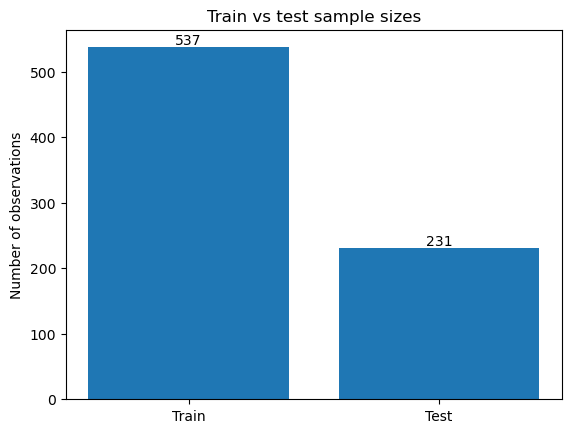

In [14]:
#Train vs test sizes with labels

sizes = [len(X_train), len(X_test)]
labels = ['Train', 'Test']

fig, ax = plt.subplots()
bars = ax.bar(labels, sizes)
ax.set_title('Train vs test sample sizes')
ax.set_ylabel('Number of observations')

for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, height, str(height),
            ha='center', va='bottom')

plt.show()


In [15]:
#Scaling for logistic regression

scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc = scaler.transform(X_test)

In [16]:
#Fitting models
log_reg = LogisticRegression(max_iter=1000)
log_reg.fit(X_train_sc, y_train)

tree = DecisionTreeClassifier(random_state=0)
tree.fit(X_train, y_train)

DecisionTreeClassifier(random_state=0)

In [17]:
#Evaluate models

for name, model, X_te in [
    ("Logistic Regression", log_reg, X_test_sc),
    ("Decision Tree", tree, X_test),
]:
    y_pred = model.predict(X_te)
    print(f"\n{name}")
    print("Accuracy:", accuracy_score(y_test, y_pred))
    print("Confusion matrix:\n", confusion_matrix(y_test, y_pred))
    print(classification_report(y_test, y_pred))



Logistic Regression
Accuracy: 0.7748917748917749
Confusion matrix:
 [[134  16]
 [ 36  45]]
              precision    recall  f1-score   support

           0       0.79      0.89      0.84       150
           1       0.74      0.56      0.63        81

    accuracy                           0.77       231
   macro avg       0.76      0.72      0.74       231
weighted avg       0.77      0.77      0.77       231


Decision Tree
Accuracy: 0.7012987012987013
Confusion matrix:
 [[115  35]
 [ 34  47]]
              precision    recall  f1-score   support

           0       0.77      0.77      0.77       150
           1       0.57      0.58      0.58        81

    accuracy                           0.70       231
   macro avg       0.67      0.67      0.67       231
weighted avg       0.70      0.70      0.70       231



LogReg AUC: 0.871522633744856


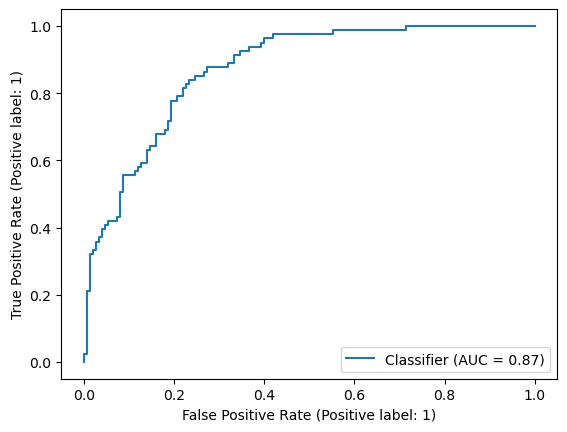

In [18]:
#Probs and ROC for logistic regression
y_prob = log_reg.predict_proba(X_test_sc)[:, 1]
print("LogReg AUC:", roc_auc_score(y_test, y_prob))
RocCurveDisplay.from_predictions(y_test, y_prob)
plt.show()